# Rock Paper Scissors Object Detection using YOLO26n

**Course:** CSCI1409 — Deep Learning  
**Assignment:** Bonus Project — Train an Object Detector  
**Dataset:** [Rock Paper Scissors, Roboflow Universe, version 44](https://universe.roboflow.com/team-roboflow/rock-paper-scissors-detection/dataset/44)  
**Classes:** Paper, Rock, Scissors  
**Annotations:** YOLO format (`class_id x_center y_center width height`)

**Goal:** Fine-tune a pretrained detector, compare 25 and 35 training epochs, evaluate the selected model on the test set, and examine three missed detections.

**Setup:** Runs in Colab or locally with the appropriate PyTorch device. Saved checkpoints are reused where available.

**Data usage:** The downloaded ZIP metadata reports `license: Private`. Do not redistribute the images publicly without permission.

## 1. Dataset Exploration and Preparation

## 0. Clean Runtime Setup (Local VS Code or Google Colab)

This notebook can run locally or in a fresh **Google Colab** runtime. For Colab, choose **Runtime → Change runtime type → GPU**, then run from the top.

**Dataset access:** The original Roboflow version 44 export lists its license as **Private**. Do not upload the dataset ZIP to a public repository without permission. Instead, download your own authorized YOLO26-format ZIP from [Roboflow Universe, version 44](https://universe.roboflow.com/team-roboflow/rock-paper-scissors-detection/dataset/44). In Colab you will be asked to **upload that original ZIP**; the notebook extracts it, repairs the paths, and reproduces the split.

**Training safety:** Saved checkpoints are reused automatically. On Mac, training is disabled by default; in a fresh Colab session **missing checkpoints are trained**. Both models start from the same original `yolo26n.pt` weights. If you use Colab's temporary storage, download the checkpoints before ending the session.

*We pin the notebook's Python dependencies; PyTorch/CUDA comes from the selected Colab runtime and its actual version is recorded below. The saved results in this notebook come from Colab on a Tesla T4 (Ultralytics 8.4.212, Python 3.13.16, PyTorch 2.14.1+cu130).*

In [ ]:
# Run this cell first in Colab or VS Code
from pathlib import Path
import os
import sys
import subprocess
import zipfile

IN_COLAB = "COLAB_RELEASE_TAG" in os.environ or "google.colab" in sys.modules

if IN_COLAB:
    repo_dir = Path("/content/rps-object-detection")

    if not repo_dir.exists():
        subprocess.run(
            [
                "git", "clone", "--depth", "1",
                "https://github.com/DaniyarIssengaliyev/rps-object-detection.git",
                str(repo_dir)
            ],
            check=True
        )

    os.chdir(repo_dir)

PROJECT_ROOT = Path.cwd().resolve()


if IN_COLAB:
    # Install the same Ultralytics release used in the original project.
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "ultralytics==8.4.212", "pandas==2.2.3",
        "matplotlib==3.10.7", "Pillow==11.3.0", "PyYAML==6.0.2"
    ])

# Use the local prepared dataset if present. Otherwise get the original ZIP.
dataset = PROJECT_ROOT / "dataset" / "Rock Paper Scissors"

if not (dataset / "data.yaml").exists():
    if IN_COLAB:
        from google.colab import files
        print("Upload your original authorized 'Rock Paper Scissors.zip' (Roboflow v44)")
        uploaded = files.upload()
        archives = [PROJECT_ROOT / name for name in uploaded if name.lower().endswith(".zip")]
        if not archives:
            raise FileNotFoundError("Please upload the Roboflow version 44 ZIP file.")
        archive = archives[0]
    else:
        archive = PROJECT_ROOT / "Rock Paper Scissors.zip"
        if not archive.exists():
            raise FileNotFoundError(
                "Dataset not found. Place 'Rock Paper Scissors.zip' in the project folder, "
                "or use your existing dataset/Rock Paper Scissors folder."
            )

    with zipfile.ZipFile(archive) as zf:
        # Export contains 'Rock Paper Scissors/train', 'valid', 'test', and data.yaml.
        zf.extractall(PROJECT_ROOT / "dataset")
    print("Extracted dataset from:", archive.name)

assert (dataset / "data.yaml").exists(), "Cannot find Rock Paper Scissors/data.yaml"
print("Dataset folder:", dataset)
print("Colab:", IN_COLAB)


## 1. Dataset Exploration and Preparation

In [11]:
from pathlib import Path
from collections import Counter
from hashlib import sha256
import random
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
import yaml
import pandas as pd

# The original Roboflow export points outside its own directory.
data_yaml = (dataset / "data.yaml").resolve()
with open(data_yaml, encoding="utf-8") as f:
    data_config = yaml.safe_load(f)

assert data_config.get("nc") == 3, "Expected 3 gesture classes."
assert data_config.get("names") == ["Paper", "Rock", "Scissors"], "Unexpected class order."
roboflow_version = data_config.get("roboflow", {}).get("version")
assert str(roboflow_version) == "44", "Use Roboflow dataset version 44."

expected_paths = {"train": "train/images", "val": "valid/images", "test": "test/images"}
if any(data_config.get(key) != value for key, value in expected_paths.items()):
    data_config.update(expected_paths)
    with open(data_yaml, "w", encoding="utf-8") as f:
        yaml.safe_dump(data_config, f, sort_keys=False, allow_unicode=True)
    print("Repaired original data.yaml paths for this folder.")
else:
    print("data.yaml paths already correct; no changes made.")

class_names = data_config["names"]
for split in ["train", "valid", "test"]:
    assert (dataset / split / "images").is_dir(), f"Missing {split}/images"
    assert (dataset / split / "labels").is_dir(), f"Missing {split}/labels"
print("Classes:", class_names)
print("Paths:", expected_paths)


Repaired original data.yaml paths for this folder.
Classes: ['Paper', 'Rock', 'Scissors']
Paths: {'train': 'train/images', 'val': 'valid/images', 'test': 'test/images'}


**Setup:** Load libraries once and inspect `data.yaml`. When using the original Roboflow ZIP, we update three relative image paths; a previously corrected local YAML is left unchanged. The source version (44), class names, and directories are verified.

### 1.1 Data Split Preparation

**Purpose:** Prevent leakage across train/validation/test from two known groups of frames of the same video.

**Method:** Move frames from the two identified videos (and matching `.txt` labels) from Valid/Test into Train. The operation is deterministic and idempotent. The original Roboflow split is otherwise retained.

In [5]:


# Keep the two identified video sources entirely in Train
video_ids = [
    "Cool-Video-of-Ocean-Fish-Swimming",
    "GMT20210709-195148_Recording_640x360"
]

moved = 0

for split in ["valid", "test"]:
    images_path = dataset / split / "images"
    labels_path = dataset / split / "labels"

    for image in images_path.iterdir():
        if not any(image.name.startswith(v + "_mp4-") for v in video_ids):
            continue

        label = labels_path / (image.stem + ".txt")
        new_image = dataset / "train" / "images" / image.name
        new_label = dataset / "train" / "labels" / label.name

        if not label.exists():
            raise FileNotFoundError(label)
        if new_image.exists() or new_label.exists():
            raise FileExistsError(image.name)

        image.rename(new_image)
        label.rename(new_label)
        moved += 1

print("Images moved in this run:", moved)
for split in ["train", "valid", "test"]:
    number = len(list((dataset / split / "images").glob("*.jpg")))
    print(f"{split}: {number} images")

Images moved in this run: 8
train: 601 images
valid: 148 images
test: 76 images


**Split result:** The corrected dataset has **601 training, 148 validation, and 76 test images** (825 total). Eight frames from two known videos were moved to Train together with their labels. Running this cell again moves zero files.

### 1.2 Dataset Statistics

**Purpose:** Count images, missing annotation files, empty annotation files, and objects per class in each split.

In [ ]:
for split in ["train", "valid", "test"]:
    images_dir = dataset / split / "images"
    labels_dir = dataset / split / "labels"

    images = [
        p for p in images_dir.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    counts = Counter()
    empty_labels = 0
    missing_labels = 0

    for image in images:
        label = labels_dir / (image.stem + ".txt")

        if not label.exists():
            missing_labels += 1
            continue

        lines = label.read_text().splitlines()
        if not lines:
            empty_labels += 1

        for line in lines:
            class_id = int(line.split()[0])
            counts[class_id] += 1

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Empty:", empty_labels)
    print("Missing:", missing_labels)
    for i, name in enumerate(class_names):
        print(f"{name}: {counts[i]}")


TRAIN
Images: 601
Empty: 186
Missing: 0
Paper: 160
Rock: 154
Scissors: 116

VALID
Images: 148
Empty: 43
Missing: 0
Paper: 38
Rock: 36
Scissors: 31

TEST
Images: 76
Empty: 14
Missing: 0
Paper: 20
Rock: 21
Scissors: 23


**Dataset statistics:** There are **599 annotated objects** across 825 images, with no missing label files. Some label files are empty (186 Train / 43 Validation / 14 Test); these may be valid background images, but they still require care when reviewing data quality.

### 1.3 Ground Truth Visualization

**Purpose:** Show five images with the bounding boxes provided by the dataset. These are *ground-truth annotations*, not predictions from YOLO.

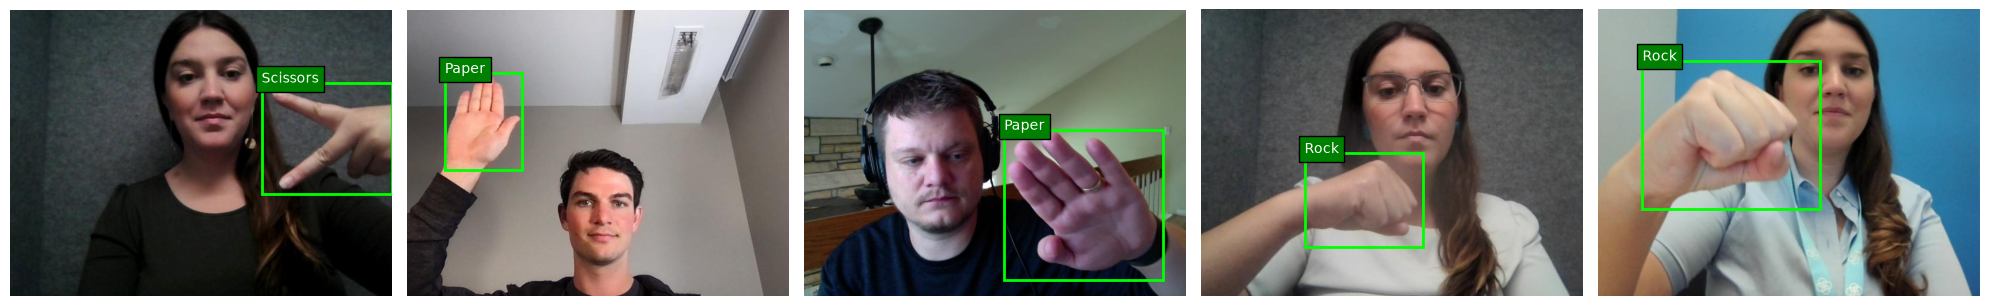

In [ ]:
viz_images_dir = dataset / "train" / "images"
viz_labels_dir = dataset / "train" / "labels"

labeled_images = []
for image in viz_images_dir.iterdir():
    if image.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
        continue

    label = viz_labels_dir / (image.stem + ".txt")
    if label.exists() and label.read_text().strip():
        labeled_images.append(image)

random.seed(42)
samples = random.sample(sorted(labeled_images), 5)
print("Labeled training images:", len(labeled_images))
print("Selected samples:", len(samples))

fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for ax, image_path in zip(axes, samples):
    image = Image.open(image_path).convert("RGB")
    width, height = image.size
    ax.imshow(image)

    label_path = viz_labels_dir / (image_path.stem + ".txt")
    lines = label_path.read_text().splitlines()

    for line in lines:
        values = line.split()
        class_id = int(values[0])
        x, y, w, h = map(float, values[1:5])

        # YOLO stores the center and size; Rectangle needs top-left pixel coordinates
        x1 = (x - w / 2) * width
        y1 = (y - h / 2) * height
        box_w = w * width
        box_h = h * height

        rect = Rectangle((x1, y1), box_w, box_h,
                         fill=False, edgecolor="lime", linewidth=2)
        ax.add_patch(rect)
        ax.text(x1, y1, class_names[class_id], color="white",
                bbox=dict(facecolor="green"))

    ax.axis("off")

plt.tight_layout()
Path("results").mkdir(exist_ok=True)
plt.savefig("results/ground_truth.png", dpi=150)
plt.show()

**Ground truth:** Five annotated training images are displayed. YOLO labels use normalized center coordinates; the code converts them to pixel coordinates and draws the reference bounding boxes. Figure: `results/ground_truth.png`.

### 1.4 Empty Annotation Inspection

**Purpose:** Inspect empty label files. An empty annotation may represent a valid background image, but it can also indicate a missed object.

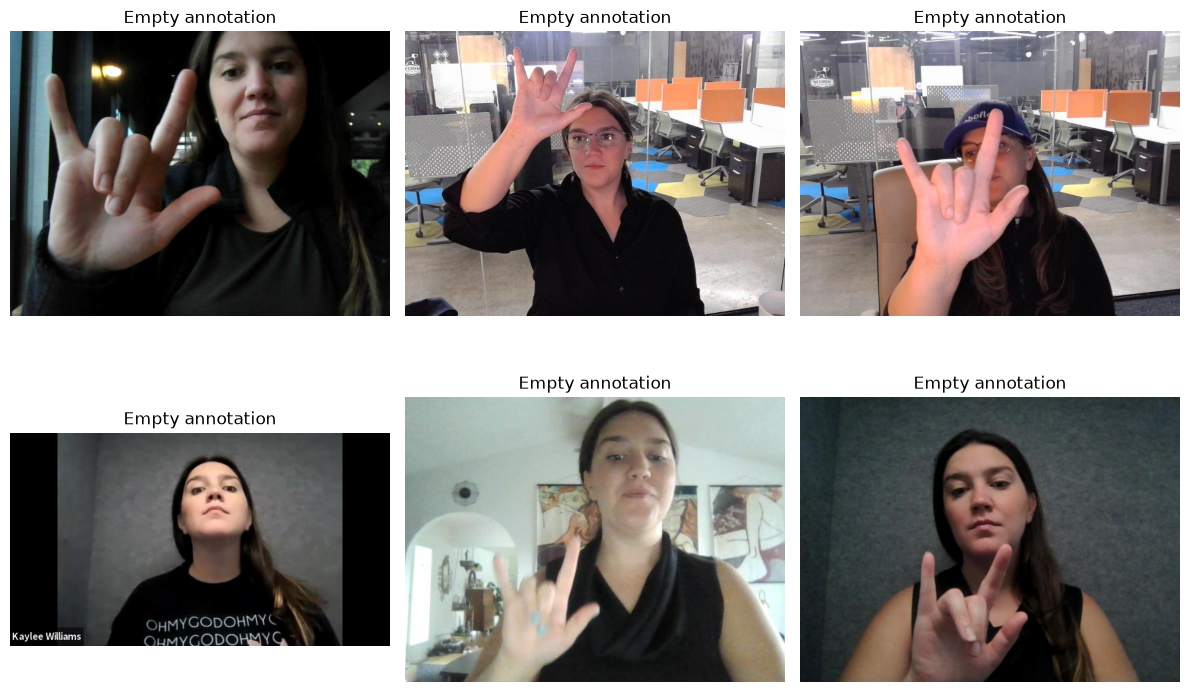

In [ ]:
empty_files = [
    label for label in viz_labels_dir.glob("*.txt")
    if not label.read_text().strip()
]

empty_stems = {label.stem for label in empty_files}
empty_images = [
    image for image in viz_images_dir.iterdir()
    if image.suffix.lower() in [".jpg", ".jpeg", ".png"]
    and image.stem in empty_stems
]

print("Empty train labels:", len(empty_files))
print("Corresponding images:", len(empty_images))

samples_empty = random.sample(sorted(empty_images), 6)
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, image_path in zip(axes.flat, samples_empty):
    image = Image.open(image_path).convert("RGB")
    ax.imshow(image)
    ax.set_title("Empty annotation")
    ax.axis("off")

plt.tight_layout()
Path("results").mkdir(exist_ok=True)
plt.savefig("results/empty_examples.png", dpi=150)
plt.show()

**Empty labels:** We show six training images without annotated objects. An empty label file is not necessarily an error; a small visual sample cannot verify every empty annotation. Figure: `results/empty_examples.png`.

### 1.5 Duplicate and Source-Video Check

**Purpose:** Detect exact copies across train/validation/test, screen for visually similar images, and check whether frames with the same `_mp4-` source prefix occur in different splits.

In [ ]:
image_hashes = {}

for split in ["train", "valid", "test"]:
    images_path = dataset / split / "images"
    for image in images_path.iterdir():
        if image.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
            continue
        file_hash = sha256(image.read_bytes()).hexdigest()
        image_hashes.setdefault(file_hash, []).append((split, image.name))

duplicates = []
for files in image_hashes.values():
    if len({split for split, name in files}) > 1:
        duplicates.append(files)

print("Exact duplicate groups across splits:", len(duplicates))

Exact duplicate groups across splits: 0


Potential cross-split near-duplicate pairs: 199
Pair 1: dHash distance = 0
Pair 2: dHash distance = 0
Pair 3: dHash distance = 0
Pair 4: dHash distance = 0


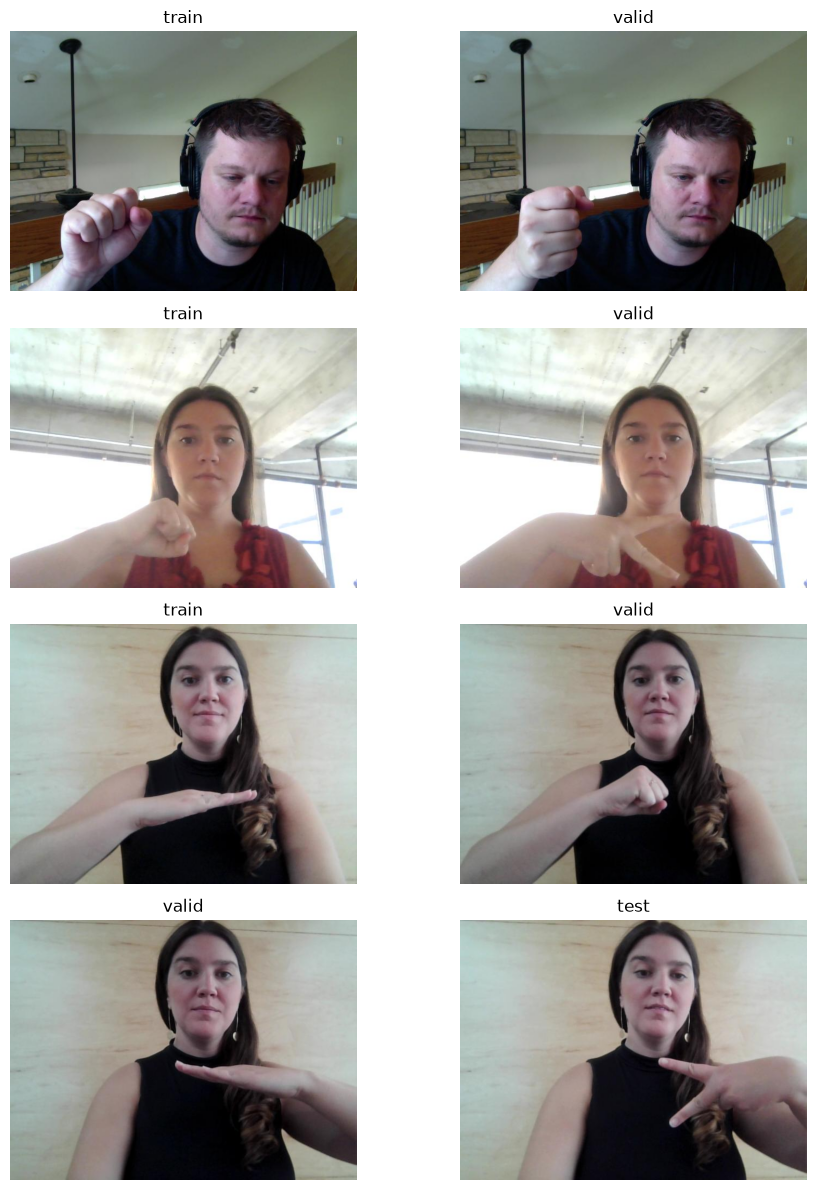

Named video sources across multiple splits: 0


In [ ]:
# A simple visual fingerprint: difference hash (dHash)
def dhash(image_path):
    with Image.open(image_path) as img:
        img = img.convert("L").resize((9, 8))
        pixels = list(img.tobytes())  # Avoid Pillow's deprecated getdata()

    bits = 0
    for row in range(8):
        for col in range(8):
            left = pixels[row * 9 + col]
            right = pixels[row * 9 + col + 1]
            bits = (bits << 1) | (left > right)
    return bits

image_data = []
for split in ["train", "valid", "test"]:
    for image in sorted((dataset / split / "images").iterdir()):
        if image.suffix.lower() in [".jpg", ".jpeg", ".png"]:
            image_data.append((split, image, dhash(image)))

near_duplicates = []
for i in range(len(image_data)):
    for j in range(i + 1, len(image_data)):
        split1, image1, hash1 = image_data[i]
        split2, image2, hash2 = image_data[j]
        if split1 == split2:
            continue
        distance = (hash1 ^ hash2).bit_count()
        if distance <= 5:
            near_duplicates.append((distance, image1, image2))

near_duplicates.sort(key=lambda pair: pair[0])
print("Potential cross-split near-duplicate pairs:", len(near_duplicates))

# Show four most similar pairs for manual review
n = min(4, len(near_duplicates))
if n > 0:
    fig, axes = plt.subplots(n, 2, figsize=(10, 3 * n), squeeze=False)
    for i, (distance, image1, image2) in enumerate(near_duplicates[:n]):
        for ax, path in zip(axes[i], [image1, image2]):
            ax.imshow(Image.open(path))
            ax.set_title(path.parent.parent.name)
            ax.axis("off")
        print(f"Pair {i+1}: dHash distance = {distance}")
    plt.tight_layout()
    plt.show()
else:
    print("No potential near-duplicate pairs found.")

# Verify frame groups detected by their filename prefixes
video_splits = {}
for split, image_path, _ in image_data:
    if "_mp4-" in image_path.name:
        video_id = image_path.name.split("_mp4-")[0]
        video_splits.setdefault(video_id, set()).add(split)

cross_split_videos = {k: v for k, v in video_splits.items() if len(v) > 1}
print("Named video sources across multiple splits:", len(cross_split_videos))

**Split integrity:** SHA-256 found no exact duplicate files across splits. A perceptual dHash check flagged 199 *possible* cross-split near-duplicate pairs; this is a screening result, not 199 confirmed duplicates. The two identified `_mp4-` video groups are now kept in Train. Other visually modified duplicates have **not** been fully ruled out, so the risk of data leakage remains a limitation.

### Dataset Summary

| Item | Result |
|---|---|
| Dataset size | 825 images |
| Classes | Paper, Rock, Scissors |
| Train / Validation / Test | 601 / 148 / 76 images |
| Annotation format | YOLO bounding boxes |
| Missing label files | 0 |
| Exact cross-split duplicates | 0 detected |
| Potential near-duplicates | 199 dHash candidate pairs, not all manually verified |

**Split method:** Keep the original Roboflow split, except for grouping the two identified video sources in Train. The correction is deterministic; `seed=42` is used for image sampling and model training, not for choosing the split.

## 2. Baseline Model Training — 25 Epochs

Fine-tune the pretrained `yolo26n.pt` model using **SGD**, learning rate **0.01**, batch size **8**, image size **640**, and seed **42** with MPS on Mac or CUDA on Colab.

**Safety:** On Mac the saved `best.pt` is reused. In fresh Colab, missing checkpoints are automatically trained once. The second run always starts from the original pretrained weights.

In [8]:
from ultralytics import YOLO
from time import perf_counter
import ultralytics
import torch

print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)

# Apple GPU locally, NVIDIA GPU in Colab, or CPU as fallback.
DEVICE = "mps" if torch.backends.mps.is_available() else (0 if torch.cuda.is_available() else "cpu")
print("Training device:", DEVICE)
if IN_COLAB and DEVICE == "cpu":
    print("TIP: Runtime > Change runtime type > GPU for faster training.")

# Local: reuse saved checkpoints. Fresh Colab: train missing checkpoints.
TRAIN_MISSING_CHECKPOINTS = IN_COLAB
training_root = PROJECT_ROOT / "runs" / "detect" / "results" / "training"
baseline_dir = training_root / "baseline"

import shutil

saved_models = {
    "baseline": "baseline_best.pt",
    "experiment_35epochs": "experiment_35epochs_best.pt"
}

for run_name, checkpoint_name in saved_models.items():
    run_dir = training_root / run_name
    weights_dir = run_dir / "weights"
    weights_dir.mkdir(parents=True, exist_ok=True)

    source = PROJECT_ROOT / "checkpoints" / checkpoint_name
    destination = weights_dir / "best.pt"

    if source.exists() and not destination.exists():
        shutil.copy2(source, destination)

    for filename in ["args.yaml", "results.csv", "results.png"]:
        destination_file = run_dir / filename
        # Support both layouts used when logs were uploaded via GitHub.
        for source_file in [
            PROJECT_ROOT / "results" / run_name / filename,
            PROJECT_ROOT / "results" / "training" / run_name / filename,
        ]:
            if source_file.is_file() and not destination_file.exists():
                shutil.copy2(source_file, destination_file)
                break

if not (baseline_dir / "weights" / "best.pt").exists():
    if not TRAIN_MISSING_CHECKPOINTS:
        raise FileNotFoundError("Missing baseline best.pt; enable training intentionally to create it.")
    baseline_model = YOLO("yolo26n.pt")
    start = perf_counter()
    baseline_model.train(
        data=str(data_yaml), epochs=25, imgsz=640, batch=8,
        device=DEVICE, optimizer="SGD", lr0=0.01, seed=42,
        workers=0, plots=True, project=str(training_root), name="baseline"
    )
    minutes = (perf_counter() - start) / 60
    (baseline_dir / "training_time.txt").write_text(f"{minutes:.2f} minutes")
else:
    print("Reusing saved baseline checkpoint (no training).")

print("Baseline best.pt:", baseline_dir / "weights" / "best.pt")


Ultralytics: 8.4.212
PyTorch: 2.14.1+cu130
Training device: 0
Reusing saved baseline checkpoint (no training).
Baseline best.pt: /content/rps-object-detection/runs/detect/results/training/baseline/weights/best.pt


**Baseline result (Colab training log)** — At the end of training, Ultralytics evaluated the saved 25-epoch run's `best.pt` on the validation split. The log reports **97.4% precision**, **94.4% recall**, **98.4% mAP@0.50**, and **66.3% mAP@0.50:0.95** at its displayed precision. Training took **0.116 hours (about 7.0 minutes)** on a Tesla T4. Section 4 reports the separate evaluation used for model selection.

## 3. Controlled Experiment — 35 Epochs

**Hypothesis:** Training for 35 instead of 25 epochs may improve detection and bounding-box localization.

Only the **number of epochs** changes. Model, initial pretrained weights (`yolo26n.pt`), split, optimizer (SGD), learning rate (0.01), batch size (8), image size (640), and seed (42) stay the same. The longer run also stretches the default learning-rate schedule.

The second run starts again from pretrained weights, **not** from the 25-epoch checkpoint. The notebook skips this run if its checkpoint already exists. In a fresh Colab session it trains automatically.

In [9]:
# Experiment 2: 35 epochs instead of 25. Everything else stays the same.
experiment_dir = training_root / "experiment_35epochs"

if not (experiment_dir / "weights" / "best.pt").exists():
    if not TRAIN_MISSING_CHECKPOINTS:
        raise FileNotFoundError("Missing experiment best.pt; enable training intentionally to create it.")
    experiment_model = YOLO("yolo26n.pt")  # NOT baseline best.pt
    start = perf_counter()
    experiment_model.train(
        data=str(data_yaml), epochs=35, imgsz=640, batch=8,
        device=DEVICE, optimizer="SGD", lr0=0.01, seed=42,
        workers=0, plots=True, project=str(training_root), name="experiment_35epochs"
    )
    minutes = (perf_counter() - start) / 60
    (experiment_dir / "training_time.txt").write_text(f"{minutes:.2f} minutes")
else:
    print("Reusing saved 35-epoch checkpoint (no training).")

print("Experiment best.pt:", experiment_dir / "weights" / "best.pt")


Reusing saved 35-epoch checkpoint (no training).
Experiment best.pt: /content/rps-object-detection/runs/detect/results/training/experiment_35epochs/weights/best.pt


**Experiment result (Colab training log)** — The 35-epoch run's `best.pt` logged **96.4% precision**, **93.9% recall**, **98.9% mAP@0.50**, and **65.9% mAP@0.50:0.95** on validation at the log's displayed precision. Training took **0.165 hours (about 9.9 minutes)** on the same Tesla T4.

## 4. Validation Results and Comparison

Compare the **best checkpoints** from both runs on the same validation set. The grouped bar chart makes the small differences visible. This step evaluates saved models; it does **not** retrain them.

Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 712.9±400.0 MB/s, size: 22.2 KB)
val: Scanning /content/rps-object-detection/dataset/Rock Paper Scissors/valid/labels... 148 images, 43 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 148/148 1.5Kit/s 0.1s
val: New cache created: /content/rps-object-detection/dataset/Rock Paper Scissors/valid/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 13.2it/s 1.4s
                   all        148        105      0.974      0.944      0.984      0.666
Speed: 0.8ms preprocess, 3.9ms inference, 0.0ms loss, 1.1ms postprocess per image
Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image 

,25 epochs,35 epochs
Precision,97.44,96.43
Recall,94.44,93.93
mAP50,98.36,98.95
mAP50-95,66.58,65.86


Selected by validation mAP@0.50: 35 epochs


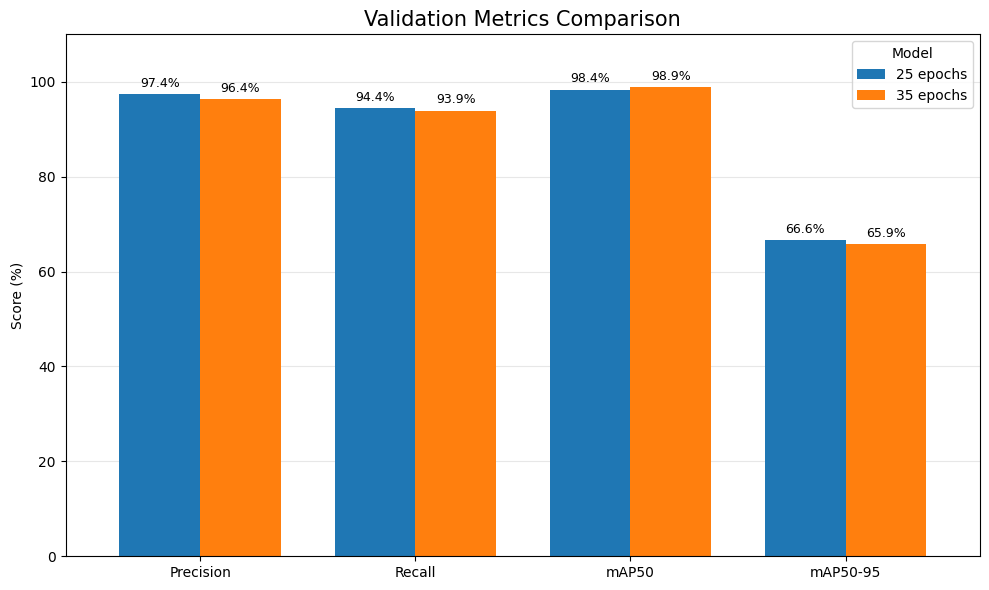

In [12]:
# Paths to the best trained models
baseline_path = baseline_dir / "weights" / "best.pt"
experiment_path = experiment_dir / "weights" / "best.pt"
models = {
    "25 epochs": baseline_path,
    "35 epochs": experiment_path
}

scores = {}

for name, checkpoint in models.items():
    model = YOLO(str(checkpoint))

    metrics = model.val(
        data=str(data_yaml),
        split="val",
        imgsz=640,
        batch=8,
        device=DEVICE,
        conf=0.001,
        iou=0.7,
        plots=False,
        verbose=False
    )

    scores[name] = {
        "Precision": metrics.box.mp * 100,
        "Recall": metrics.box.mr * 100,
        "mAP50": metrics.box.map50 * 100,
        "mAP50-95": metrics.box.map * 100
    }

comparison_df = pd.DataFrame(scores)

display(comparison_df.round(2))

fig, ax = plt.subplots(figsize=(10, 6))

comparison_df.plot(
    kind="bar",
    ax=ax,
    width=0.75
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3,
        fontsize=9
    )

ax.set_title("Validation Metrics Comparison", fontsize=15)
ax.set_xlabel("")
ax.set_ylabel("Score (%)")
ax.set_ylim(0, 110)
ax.legend(title="Model")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()

comparison_dir = Path("results/comparison")
comparison_dir.mkdir(parents=True, exist_ok=True)
comparison_df.T.to_csv(comparison_dir / "validation_metrics.csv")

# Select final model *from validation*, not from test results.
selected_name = comparison_df.loc["mAP50"].idxmax()
selected_checkpoint = models[selected_name]
print("Selected by validation mAP@0.50:", selected_name)

plt.savefig(
    comparison_dir / "validation_metrics_comparison.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


The two saved `best.pt` checkpoints were evaluated on the same 148 validation images (105 annotated objects). The table matches `results/comparison/validation_metrics.csv` and the comparison output.

| Training run | Precision | Recall | mAP@0.50 | mAP@0.50:0.95 |
|---|---:|---:|---:|---:|
| 25 epochs | 97.44% | 94.44% | 98.36% | 66.58% |
| 35 epochs | 96.43% | 93.93% | 98.95% | 65.86% |

**Selected checkpoint** — The **35-epoch YOLO26n** scored **98.95%** on the validation selection metric, **mAP@0.50**, versus **98.36%** for the 25-epoch model (a gain of **0.59 percentage points**). The 25-epoch checkpoint scored higher on precision, recall, and mAP@0.50:0.95. The 35-epoch run took about **2.9 minutes** longer.

### Validation Curves by Epoch

These plots read the training logs (`results.csv`) directly, so they show **how performance changed during training**, not just the final scores.

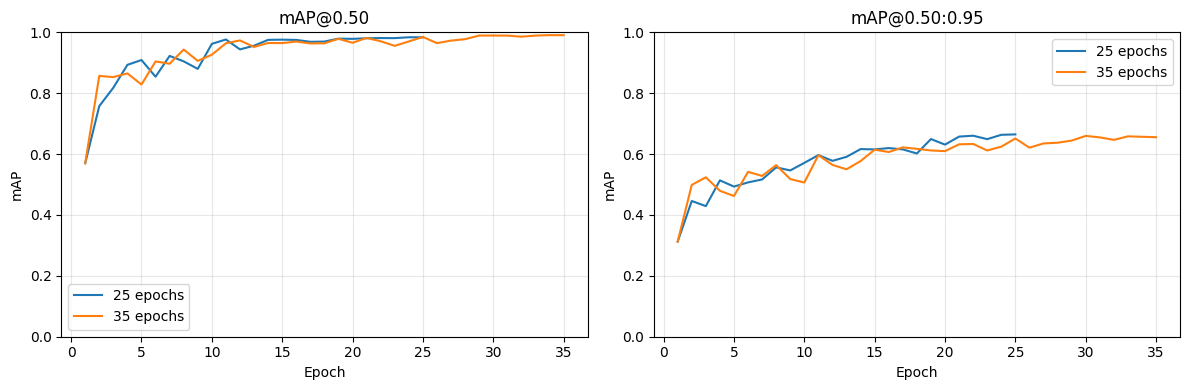

In [ ]:
# Plot validation mAP across epochs (no training)
baseline_log_path = baseline_dir / "results.csv"
experiment_log_path = experiment_dir / "results.csv"
if not baseline_log_path.is_file() or not experiment_log_path.is_file():
    raise FileNotFoundError(
        "Training CSV logs are needed for this plot. Download results/baseline "
        "and results/experiment_35epochs (or results/training/...) from GitHub."
    )
baseline_log = pd.read_csv(baseline_log_path)
experiment_log = pd.read_csv(experiment_log_path)

baseline_log.columns = baseline_log.columns.str.strip()
experiment_log.columns = experiment_log.columns.str.strip()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, metric, title in zip(
    axes,
    ["metrics/mAP50(B)", "metrics/mAP50-95(B)"],
    ["mAP@0.50", "mAP@0.50:0.95"]
):
    ax.plot(baseline_log["epoch"], baseline_log[metric], label="25 epochs")
    ax.plot(experiment_log["epoch"], experiment_log[metric], label="35 epochs")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("mAP")
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)
    ax.legend()
fig.suptitle("Training Curves — MacBook M5 Runs", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.92])
comparison_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(comparison_dir / "validation_curves.png", dpi=150)
plt.show()

**Reading the curves:** The plots show validation mAP across all 25 and 35 epochs. Section 4 uses the separate evaluation of each saved `best.pt` checkpoint to select the final model.

## 5. Final Test Evaluation

Colab selected the **35-epoch YOLO26n** by validation mAP@0.50 before evaluating it on the held-out test split of **76 images and 64 annotated objects**.

The evaluation reports precision, recall, mAP@0.50, and mAP@0.50:0.95. The evaluation call uses a confidence threshold of 0.001 and sets `iou=0.7`.


In [13]:

# Final Test Evaluation

# Load the selected model
final_checkpoint = selected_checkpoint

assert final_checkpoint.exists(), "Best checkpoint not found!"

final_model = YOLO(str(final_checkpoint))

# Evaluate on the held-out test dataset
test_metrics = final_model.val(
    data=str(data_yaml),
    split="test",
    imgsz=640,
    batch=8,
    device=DEVICE,
    conf=0.001,
    iou=0.7,
    plots=True,
    project=str(Path("results/evaluation").resolve()),
    name="final_test",
    exist_ok=True
)

# Collect test metrics
test_df = pd.DataFrame({
    "Metric": [
        "Precision",
        "Recall",
        "mAP@0.50",
        "mAP@0.50:0.95"
    ],
    "Test Score (%)": [
        test_metrics.box.mp * 100,
        test_metrics.box.mr * 100,
        test_metrics.box.map50 * 100,
        test_metrics.box.map * 100
    ]
})

display(test_df.round(2))

# Save results
test_df.to_csv(
    Path("results/evaluation/final_test") / "test_metrics.csv",
    index=False
)

print("Test evaluation completed for:", selected_name)


Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 676.4±333.8 MB/s, size: 28.3 KB)
val: Scanning /content/rps-object-detection/dataset/Rock Paper Scissors/test/labels... 76 images, 14 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 76/76 1.8Kit/s 0.0s
val: New cache created: /content/rps-object-detection/dataset/Rock Paper Scissors/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 4.9it/s 2.0s
                   all         76         64      0.993      0.873      0.947      0.595
                 Paper         20         20          1      0.936      0.945      0.634
                  Rock         20         21      0.979      0.905      0.982      0.572
              Scissors         23         23          1      0.778      0.915      0.577
Spee

,Metric,Test Score (%)
0,Precision,99.29
1,Recall,87.28
2,mAP@0.50,94.72
3,mAP@0.50:0.95,59.45


Test evaluation completed for: 35 epochs


**Final test result (Colab)** — The 35-epoch model achieved **99.29% precision**, **87.28% recall**, **94.72% mAP@0.50**, and **59.45% mAP@0.50:0.95**. These values match `results/evaluation/final_test/test_metrics.csv`.

The test log reports class recall of **93.6% for Paper**, **90.5% for Rock**, and **77.8% for Scissors**. Scissors had the lowest recall of the three classes.

## 6. Prediction Visualization

The panel selects five test images **by their predicted class** (two Paper, two Rock and one Scissors) using the checkpoint selected on validation. Each image displays bounding boxes, predicted class names and confidence scores at `conf=0.25`. These are selected qualitative examples, not a random sample of test performance; Section 7 separately shows failure cases.


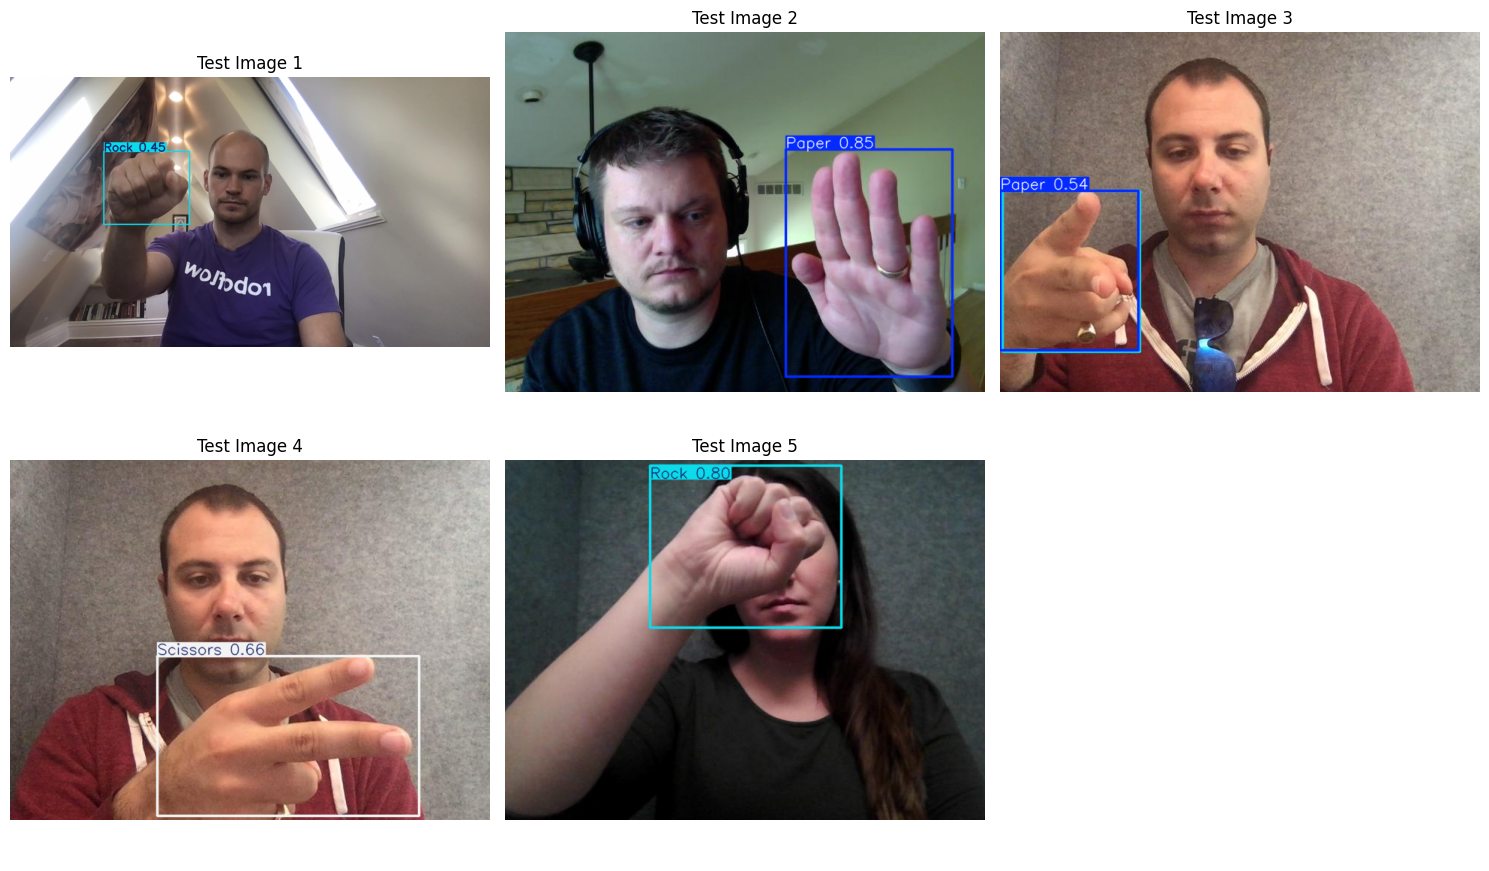

Saved 5 prediction images to: /content/rps-object-detection/results/evaluation/final_test/test_predictions_by_class.png


In [15]:

# Display five test predictions with boxes, classes and confidence scores.
test_root = Path(data_yaml).parent / "test"
test_images_dir = test_root / "images"
test_labels_dir = test_root / "labels"

model = final_model
test_images = sorted(test_images_dir.glob("*"))

needed = {0: 2, 1: 2, 2: 1}
selected = []

for image_path in test_images:
    if image_path.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
        continue

    result = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.25,
        iou=0.7,
        device=DEVICE,
        verbose=False
    )[0]

    classes = result.boxes.cls.int().tolist()

    for class_id in needed:
        if class_id in classes and needed[class_id] > 0:
            selected.append((image_path, result))
            needed[class_id] -= 1
            break

    if len(selected) == 5:
        break

assert len(selected) == 5, f"Expected 5 examples, found {len(selected)}"

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax in axes.flat:
    ax.axis("off")

for i, (image_path, result) in enumerate(selected):
    axes.flat[i].imshow(result.plot()[..., ::-1])
    axes.flat[i].set_title(f"Test Image {i + 1}")

plt.tight_layout()

output = PROJECT_ROOT / "results/evaluation/final_test/test_predictions_by_class.png"
output.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(output, dpi=150, bbox_inches="tight")
plt.show()

print(f"Saved {len(selected)} prediction images to:", output)


**Exported prediction examples:** The panel saves five detections selected by predicted class to `results/evaluation/final_test/test_predictions_by_class.png`. An older `test_predictions_5.png` may also be present in the repository; it came from a separate gallery that has been removed from this cleaned notebook.

## 7. Failure Analysis — Three Examples of Complete Misses

The code finds test images with at least one ground-truth annotation and zero predicted boxes at `conf=0.25` (`iou=0.7` in the prediction call). The figure shows the first three such images in filename order, with ground-truth boxes on the left and no detections on the right.


Images with a missed detection: 4
Failure examples available: 3


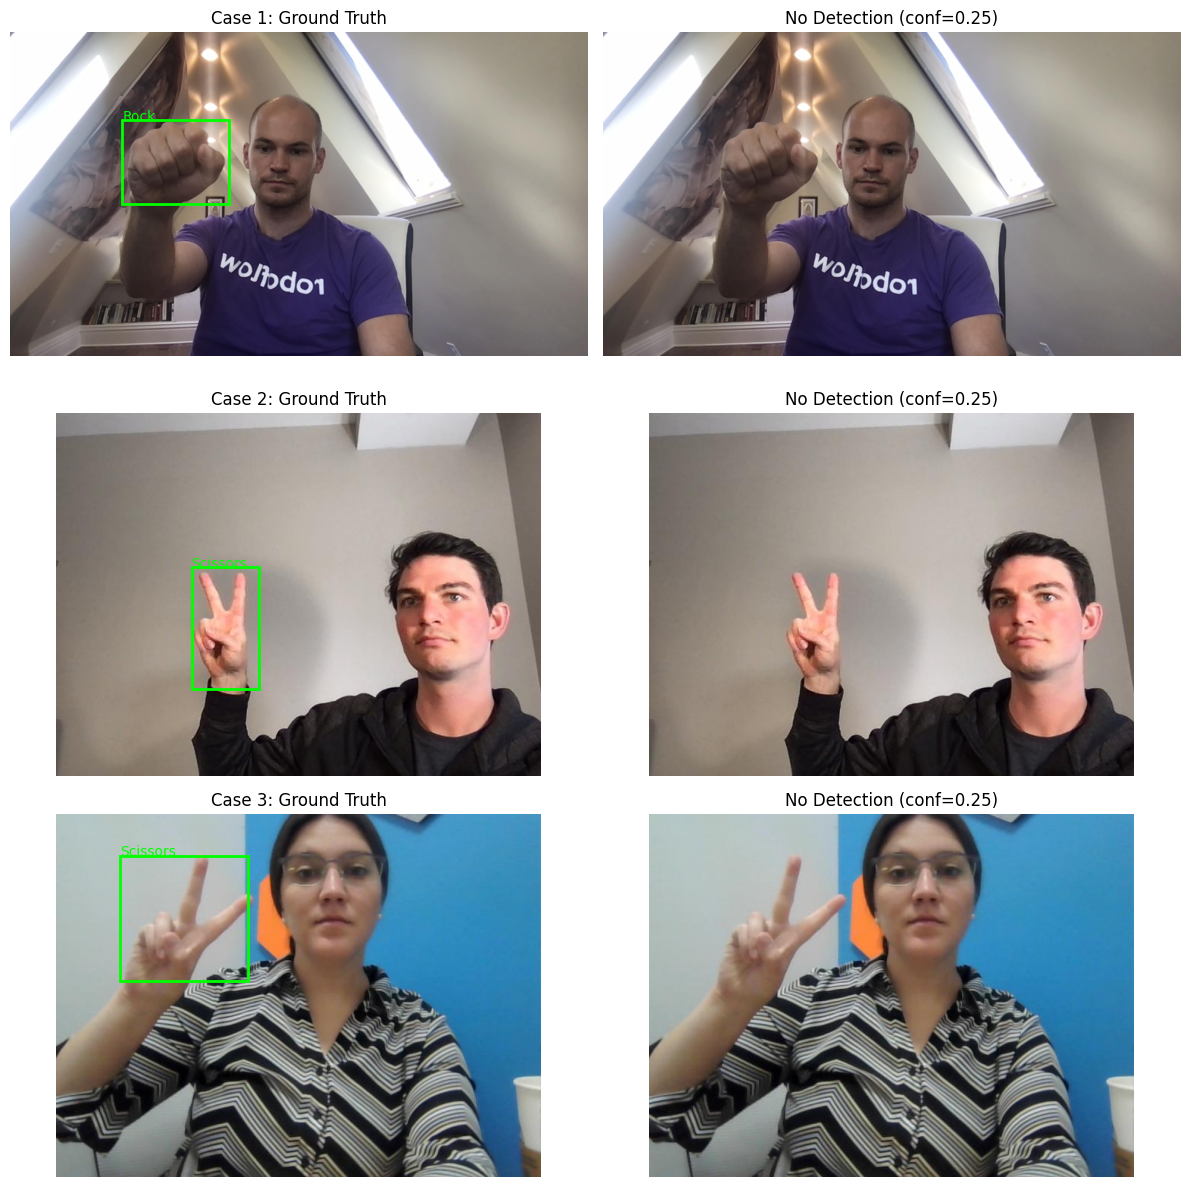

In [16]:
# Find test images where YOLO predicts no objects (conf=0.25)
test_images = sorted([
    p for p in test_images_dir.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
])

test_predictions = final_model.predict(
    source=[str(p) for p in test_images],
    imgsz=640,
    conf=0.25,
    iou=0.7,
    device=DEVICE,
    verbose=False
)

missed_images = []
for image_path, result in zip(test_images, test_predictions):
    label_path = test_labels_dir / f"{image_path.stem}.txt"
    if label_path.exists() and label_path.read_text().strip() and len(result.boxes) == 0:
        missed_images.append(image_path)

print("Images with a missed detection:", len(missed_images))

# Show three examples: ground truth (left) and no detection (right)
sample_misses = missed_images[:3]
print("Failure examples available:", len(sample_misses))

if sample_misses:
    fig, axes = plt.subplots(len(sample_misses), 2, figsize=(12, 4 * len(sample_misses)), squeeze=False)

    for i, image_path in enumerate(sample_misses):
        image = Image.open(image_path).convert("RGB")
        width, height = image.size

        axes[i, 0].imshow(image)
        axes[i, 1].imshow(image)

        label_path = test_labels_dir / f"{image_path.stem}.txt"
        for line in label_path.read_text().splitlines():
            cls, x, y, w, h = map(float, line.split()[:5])
            x1 = (x - w / 2) * width
            y1 = (y - h / 2) * height

            axes[i, 0].add_patch(Rectangle(
                (x1, y1), w * width, h * height,
                fill=False, edgecolor="lime", linewidth=2
            ))
            axes[i, 0].text(x1, y1, final_model.names[int(cls)], color="lime")

        axes[i, 0].set_title(f"Case {i + 1}: Ground Truth")
        axes[i, 1].set_title("No Detection (conf=0.25)")
        for ax in axes[i]:
            ax.axis("off")

    plt.tight_layout()
    failure_dir = Path("results/evaluation/final_test")
    failure_dir.mkdir(parents=True, exist_ok=True)
    plt.savefig(failure_dir / "failure_analysis.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("No complete missed-detection examples at conf=0.25; inspect predictions manually.")


### Failure Analysis Results

The selected 35-epoch model returned **zero boxes on four annotated test images** at `conf=0.25`. The three examples shown below the failure-analysis code and in `failure_analysis.png` contain one Rock and two Scissors annotations.

- **Case 1 — Rock.** A closed fist points toward the camera under a sloped ceiling. The foreshortened pose and strong lighting may have contributed to the miss.
- **Case 2 — Scissors.** The two raised fingers occupy a small area to the left of the person's face against a plain wall. The gesture's scale may have contributed to the miss.
- **Case 3 — Scissors.** The hand is tilted beside the person's face, with light and blue walls behind it. The hand angle and background may have contributed to the miss.

These visual features suggest hypotheses about the misses. Test recall was lowest for Scissors (**77.8%**). The four-image count measures complete misses at the visualization threshold. The test metrics use a separate evaluation at `conf=0.001`, including box matching.

**Possible Improvements**

- **Case 1 — Rock:** Add more training images with different lighting conditions and hands close to the camera.
- **Case 2 — Scissors:** Include more examples of small hand gestures at different distances.
- **Case 3 — Scissors:** Use data augmentation with different hand angles and backgrounds.

**Next step:** Fine-tune the model using more diverse Scissors examples and compare validation recall before and after training.

## 8. Reproducibility and Submission

The notebook can prepare the original Roboflow v44 ZIP locally or in a clean Colab runtime, repair relative paths, group the known video frames, train the two models if checkpoints are missing, compare validation metrics, select the final checkpoint, and evaluate once on Test.

**Limitations:** Some perceptual near-duplicate candidates across splits remain unverified. These are not confirmed duplicates, but possible leakage cannot be ruled out. Validation/test values may differ on other GPU backends despite seed 42.

### 8.1 Save the Final Artifacts

The export cell bundles `checkpoints/baseline_best.pt`, `checkpoints/experiment_35epochs_best.pt`, and the contents of `results/` into `rps_results_and_checkpoints.zip`. The Colab archive contains the comparison and test CSVs, plots, and both checkpoints. The dataset is excluded.


In [ ]:
# Save both checkpoints and exported figures for the GitHub submission
import shutil

checkpoint_dir = PROJECT_ROOT / "checkpoints"
checkpoint_dir.mkdir(parents=True, exist_ok=True)

shutil.copy2(baseline_path, checkpoint_dir / "baseline_best.pt")
shutil.copy2(experiment_path, checkpoint_dir / "experiment_35epochs_best.pt")

from zipfile import ZipFile
artifact_zip = PROJECT_ROOT / "rps_results_and_checkpoints.zip"

with ZipFile(artifact_zip, "w") as archive:
    for folder in [checkpoint_dir, PROJECT_ROOT / "results"]:
        if folder.exists():
            for file in folder.rglob("*"):
                if file.is_file():
                    archive.write(file, file.relative_to(PROJECT_ROOT))

print("Saved both checkpoints in:", checkpoint_dir)
print("Results ZIP:", artifact_zip)

# Download the ZIP manually from the Colab Files sidebar if needed.
